# SleepSync – Sleep & Mood Relationship Analyzer

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
demographic = pd.read_csv("dataset/demographic.csv")
phq = pd.read_csv("dataset/phq9.csv")
gad = pd.read_csv("dataset/gad7.csv")
isi = pd.read_csv("dataset/isi.csv")
pss = pd.read_csv("dataset/pss.csv")

In [4]:
print("Demographic shape:", demographic.shape)
print("PHQ-9 shape:", phq.shape)
print("GAD-7 shape:", gad.shape)
print("ISI shape:", isi.shape)
print("PSS shape:", pss.shape)

Demographic shape: (24292, 6)
PHQ-9 shape: (24292, 20)
GAD-7 shape: (24292, 16)
ISI shape: (24292, 16)
PSS shape: (24292, 30)


In [5]:
print(demographic.head())

   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   
3      61738  female  23.0  bachelor's degree  never smokes   
4      61739  female  21.0  bachelor's degree  never smokes   

                                         drink  
0                                 never drinks  
1                                 never drinks  
2  drinks occasionally (less than once a week)  
3                                 never drinks  
4                                 never drinks  


In [6]:
print(phq.head())

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      0          0   2.47          0   1.23          0   1.12   
1      61809      0          0   8.22          0   7.08          0   1.24   
2      61737      0          0   1.88          0   1.65          0   1.00   
3      61738      0          0   1.74          0   2.02          0   2.26   
4      61739      2          1   5.54          0   2.57          0   1.30   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          0   1.73          0   4.74          0   1.32          0   0.16   
1          0   1.08          0   1.77          0   1.26          0   1.05   
2          0   1.18          0   0.81          0   1.29          0   4.17   
3          0   0.76          0   0.59          0   0.62          0   0.54   
4          0   2.19          0   1.08          1   3.33          0   3.13   

   question8  time8  question9  time9  
0          0  12.99          0   4

In [7]:
print("PHQ-9 columns:", phq.columns.tolist())

PHQ-9 columns: ['export_id', 'score', 'question1', 'time1', 'question2', 'time2', 'question3', 'time3', 'question4', 'time4', 'question5', 'time5', 'question6', 'time6', 'question7', 'time7', 'question8', 'time8', 'question9', 'time9']


In [8]:
phq_items = phq[["export_id"] + ["question" + str(i) for i in range(1, 10)]].copy()
phq_items.columns = ["export_id"] + ["phq_" + str(i) for i in range(1, 10)]
phq_items["phq_total"] = phq["score"]

In [9]:
gad_items = gad[["export_id"] + ["question" + str(i) for i in range(1, 8)]].copy()
gad_items.columns = ["export_id"] + ["gad_" + str(i) for i in range(1, 8)]
gad_items["gad_total"] = gad["score"]

In [10]:
isi_items = isi[["export_id"] + ["question" + str(i) for i in range(1, 8)]].copy()
isi_items.columns = ["export_id"] + ["isi_" + str(i) for i in range(1, 8)]
isi_items["isi_total"] = isi["score"]

In [11]:
pss_total = pss[["export_id", "score"]].copy()
pss_total.columns = ["export_id", "pss_total"]

In [12]:
df = demographic.merge(phq_items, on="export_id")
print("After PHQ-9 merge:", df.shape)

After PHQ-9 merge: (24292, 16)


In [13]:
df = df.merge(gad_items, on="export_id")
print("After GAD-7 merge:", df.shape)

After GAD-7 merge: (24292, 24)


In [14]:
df = df.merge(isi_items, on="export_id")
print("After ISI merge:", df.shape)

After ISI merge: (24292, 32)


In [15]:
df = df.merge(pss_total, on="export_id")
print("After PSS merge:", df.shape)

After PSS merge: (24292, 33)


In [16]:
print("Merged dataset shape:", df.shape)
print(df.columns.tolist())

Merged dataset shape: (24292, 33)
['export_id', 'gender', 'age', 'edu', 'smoke', 'drink', 'phq_1', 'phq_2', 'phq_3', 'phq_4', 'phq_5', 'phq_6', 'phq_7', 'phq_8', 'phq_9', 'phq_total', 'gad_1', 'gad_2', 'gad_3', 'gad_4', 'gad_5', 'gad_6', 'gad_7', 'gad_total', 'isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'isi_total', 'pss_total']


In [17]:
df.head()

,export_id,gender,age,edu,smoke,drink,phq_1,phq_2,phq_3,phq_4,...,gad_total,isi_1,isi_2,isi_3,isi_4,isi_5,isi_6,isi_7,isi_total,pss_total
0,61793,female,19.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
1,61809,female,18.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,21
2,61737,male,40.0,master's degree,never smokes,drinks occasionally (less than once a week),0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,61738,female,23.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,28
4,61739,female,21.0,bachelor's degree,never smokes,never drinks,1,0,0,0,...,0,0,0,0,0,0,0,0,0,16


In [18]:
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (24292, 33)
   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   
3      61738  female  23.0  bachelor's degree  never smokes   
4      61739  female  21.0  bachelor's degree  never smokes   

                                         drink  phq_1  phq_2  phq_3  phq_4  \
0                                 never drinks      0      0      0      0   
1                                 never drinks      0      0      0      0   
2  drinks occasionally (less than once a week)      0      0      0      0   
3                                 never drinks      0      0      0      0   
4                                 never drinks      1      0      0      0   

   ...  gad_total  isi_1  isi_2  isi_3  isi_4  isi_5  isi_6  isi_7  isi_total  \
0  ...          0      0      0      0      

In [19]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 24292 entries, 0 to 24291
Data columns (total 33 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   export_id  24292 non-null  int64  
 1   gender     24292 non-null  str    
 2   age        24292 non-null  float64
 3   edu        24292 non-null  str    
 4   smoke      24292 non-null  str    
 5   drink      24292 non-null  str    
 6   phq_1      24292 non-null  int64  
 7   phq_2      24292 non-null  int64  
 8   phq_3      24292 non-null  int64  
 9   phq_4      24292 non-null  int64  
 10  phq_5      24292 non-null  int64  
 11  phq_6      24292 non-null  int64  
 12  phq_7      24292 non-null  int64  
 13  phq_8      24292 non-null  int64  
 14  phq_9      24292 non-null  int64  
 15  phq_total  24292 non-null  int64  
 16  gad_1      24292 non-null  int64  
 17  gad_2      24292 non-null  int64  
 18  gad_3      24292 non-null  int64  
 19  gad_4      24292 non-null  int64  
 20  gad_5      24292 

In [20]:
df.describe()

,export_id,age,phq_1,phq_2,phq_3,phq_4,phq_5,phq_6,phq_7,phq_8,...,gad_total,isi_1,isi_2,isi_3,isi_4,isi_5,isi_6,isi_7,isi_total,pss_total
count,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,...,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000
mean,73894.702536,20.655730,0.536720,0.464474,0.442409,0.494443,0.339865,0.387494,0.350074,0.164499,...,1.914128,0.396139,0.237980,0.234892,0.675078,0.536926,0.312407,0.384159,2.777581,19.991191
std,7028.103647,2.408713,0.641435,0.577255,0.672949,0.630952,0.594323,0.605558,0.610145,0.433398,...,2.919028,0.700599,0.575502,0.566361,0.809468,0.686918,0.609171,0.642806,3.437386,8.320719
min,61737.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,67809.750000,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000
50%,73885.500000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,20.000000
75%,79977.250000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,...,3.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,4.000000,27.000000
max,101310.000000,99.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,21.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,28.000000,56.000000


In [21]:
print(df.isnull().sum().sum())

0


In [22]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student ids:", df["export_id"].duplicated().sum())

Duplicate rows: 0
Duplicate student ids: 0


In [23]:
for col in ["gender", "edu", "smoke", "drink"]:
    print("\n", col)
    print(df[col].value_counts())


 gender
gender
female    15545
male       8747
Name: count, dtype: int64

 edu
edu
bachelor's degree    22290
associate degree      1285
master's degree        675
doctorate degree        42
Name: count, dtype: int64

 smoke
smoke
never smokes                                                              22513
occasional smoker (cumulative smoking <10 packs)                           1044
current smoker (cumulative smoking >10 packs)                               542
former smoker (cumulative smoking >10 packs), but not in the past year      193
Name: count, dtype: int64

 drink
drink
never drinks                                                           16404
drinks occasionally (less than once a week)                             7359
drank in the past (more than once a week), but not in the past year      284
current regular drinker (more than once a week)                          245
Name: count, dtype: int64


In [24]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())
print("Students with age below 16:", (df["age"] < 16).sum())
print("Students with age above 40:", (df["age"] > 40).sum())

Minimum age: 1.0
Maximum age: 99.0
Students with age below 16: 22
Students with age above 40: 18


In [25]:
phq_cols = ["phq_" + str(i) for i in range(1, 10)]
gad_cols = ["gad_" + str(i) for i in range(1, 8)]
isi_cols = ["isi_" + str(i) for i in range(1, 8)]

In [26]:
print("PHQ-9 total matches item sum:", (df[phq_cols].sum(axis=1) == df["phq_total"]).mean())
print("GAD-7 total matches item sum:", (df[gad_cols].sum(axis=1) == df["gad_total"]).mean())
print("ISI total matches item sum:", (df[isi_cols].sum(axis=1) == df["isi_total"]).mean())

PHQ-9 total matches item sum: 1.0
GAD-7 total matches item sum: 1.0
ISI total matches item sum: 1.0


In [27]:
print("PHQ-9 item range:", df[phq_cols].min().min(), "to", df[phq_cols].max().max())
print("GAD-7 item range:", df[gad_cols].min().min(), "to", df[gad_cols].max().max())
print("ISI item range:", df[isi_cols].min().min(), "to", df[isi_cols].max().max())

PHQ-9 item range: 0 to 3
GAD-7 item range: 0 to 3
ISI item range: 0 to 4


In [28]:
print("PHQ-9 total range:", df["phq_total"].min(), "to", df["phq_total"].max(), "(possible 0 to 27)")
print("GAD-7 total range:", df["gad_total"].min(), "to", df["gad_total"].max(), "(possible 0 to 21)")
print("ISI total range:", df["isi_total"].min(), "to", df["isi_total"].max(), "(possible 0 to 28)")
print("PSS total range:", df["pss_total"].min(), "to", df["pss_total"].max(), "(possible 0 to 56)")

PHQ-9 total range: 0 to 27 (possible 0 to 27)
GAD-7 total range: 0 to 21 (possible 0 to 21)
ISI total range: 0 to 28 (possible 0 to 28)
PSS total range: 0 to 56 (possible 0 to 56)


In [29]:
print("Correlation between PHQ-9 question 3 and ISI total:", round(df["phq_3"].corr(df["isi_total"]), 2))

Correlation between PHQ-9 question 3 and ISI total: 0.63


In [30]:
print("Dataset shape:", df.shape)

Dataset shape: (24292, 33)


In [31]:
df.columns = df.columns.str.strip()

In [32]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().str.lower()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_7552\1452289883.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [33]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student ids:", df["export_id"].duplicated().sum())

Duplicate rows: 0
Duplicate student ids: 0


In [34]:
df = df.drop_duplicates()
df = df.drop_duplicates(subset="export_id")

In [35]:
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (24292, 33)


In [36]:
print(df.isnull().sum().sum())

0


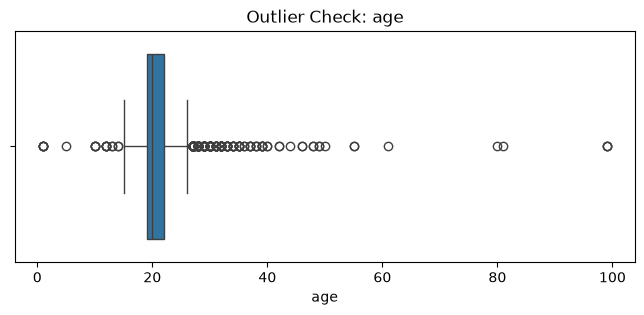

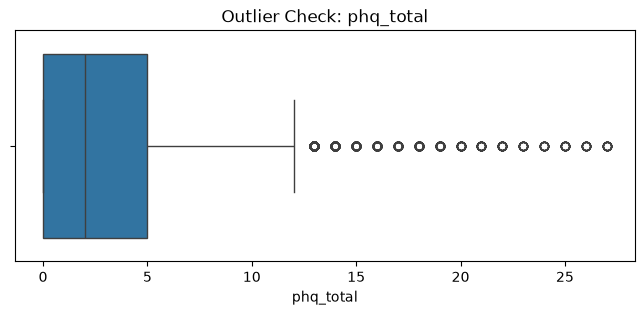

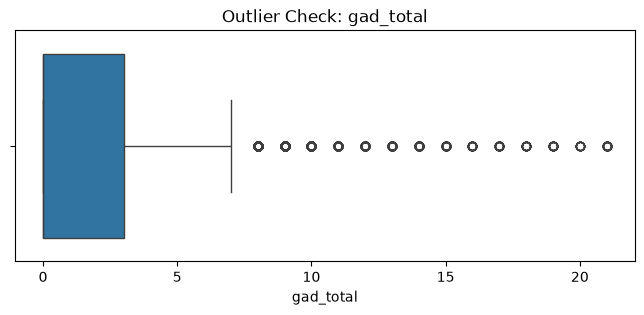

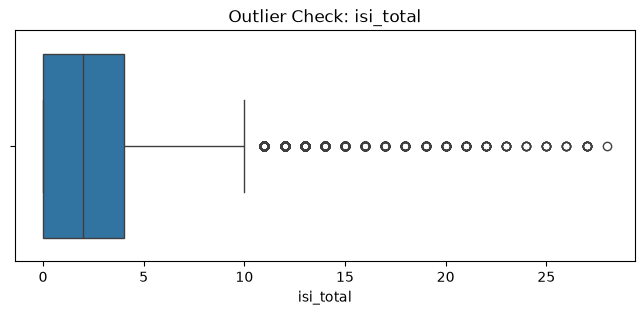

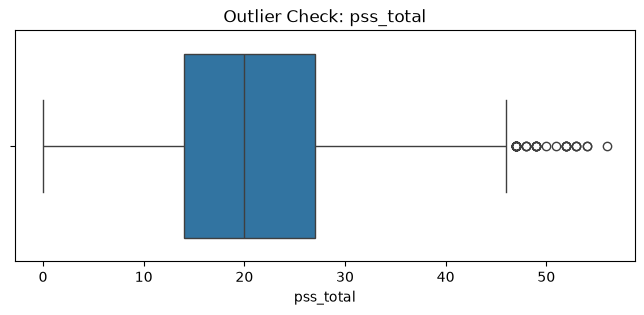

In [37]:
num_cols = ["age", "phq_total", "gad_total", "isi_total", "pss_total"]
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title("Outlier Check: " + col)
    plt.show()

In [38]:
outlier_results = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

   Column  Lower Bound  Upper Bound  Flagged Values
      age         14.5         26.5             299
phq_total         -7.5         12.5             605
gad_total         -4.5          7.5            1004
isi_total         -6.0         10.0             939
pss_total         -5.5         46.5              40


In [39]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 1.0
Maximum age: 99.0


In [40]:
invalid_age = (df["age"] < 16) | (df["age"] > 40)
print("Rows with invalid age:", invalid_age.sum())

Rows with invalid age: 40


In [41]:
df = df[~invalid_age].copy()
print("Dataset shape after age filter:", df.shape)

Dataset shape after age filter: (24252, 33)


In [42]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 16.0
Maximum age: 40.0


In [43]:
phq_no_sleep = ["phq_" + str(i) for i in range(1, 10) if i != 3]
print(phq_no_sleep)

['phq_1', 'phq_2', 'phq_4', 'phq_5', 'phq_6', 'phq_7', 'phq_8', 'phq_9']


In [44]:
df["mood_score"] = df[phq_no_sleep].sum(axis=1)
print(df["mood_score"].describe())

count    24252.000000
mean         2.820015
std          3.238282
min          0.000000
25%          0.000000
50%          2.000000
75%          5.000000
max         24.000000
Name: mood_score, dtype: float64


In [45]:
df["anxiety_score"] = df["gad_total"]

In [46]:
df["female"] = (df["gender"] == "female").astype(int)

The target low_mood is 1 when the mood score is 5 or more (mild or higher mood symptoms on the PHQ-9 scale). The usual PHQ-9 cutoff of 10 would flag only about 4% of students, which is too few for a model to learn from.

In [47]:
for t in [5, 8, 10]:
    print("Mood score >=", t, ":", round((df["mood_score"] >= t).mean() * 100, 2), "% of students")

Mood score >= 5 : 25.61 % of students
Mood score >= 8 : 7.87 % of students
Mood score >= 10 : 3.69 % of students


In [48]:
df["low_mood"] = (df["mood_score"] >= 5).astype(int)
print(df["low_mood"].value_counts())
print(df["low_mood"].value_counts(normalize=True).round(3))

low_mood
0    18040
1     6212
Name: count, dtype: int64
low_mood
0    0.744
1    0.256
Name: proportion, dtype: float64


In [49]:
df["sleep_group"] = pd.cut(
    df["isi_total"],
    bins=[-1, 7, 14, 28],
    labels=["No problem", "Mild", "Moderate or severe"]
)
print(df["sleep_group"].value_counts())

sleep_group
No problem            22058
Mild                   1916
Moderate or severe      278
Name: count, dtype: int64


In [50]:
print("Dataset shape:", df.shape)
print(df.isnull().sum().sum())

Dataset shape: (24252, 38)
0


In [51]:
df.to_csv("cleaned_data.csv", index=False)
print("cleaned_data.csv saved")

cleaned_data.csv saved


In [52]:
print("Dataset shape:", df.shape)

Dataset shape: (24252, 38)


low_mood
0    0.744
1    0.256
Name: proportion, dtype: float64


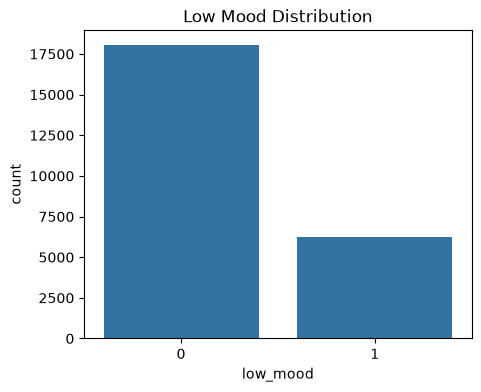

In [53]:
print(df["low_mood"].value_counts(normalize=True).round(3))
plt.figure(figsize=(5, 4))
sns.countplot(x="low_mood", data=df)
plt.title("Low Mood Distribution")
plt.show()

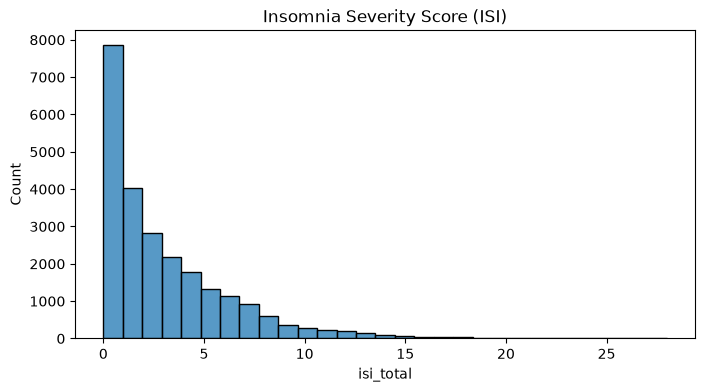

In [54]:
plt.figure(figsize=(8, 4))
sns.histplot(df["isi_total"], bins=29)
plt.title("Insomnia Severity Score (ISI)")
plt.show()

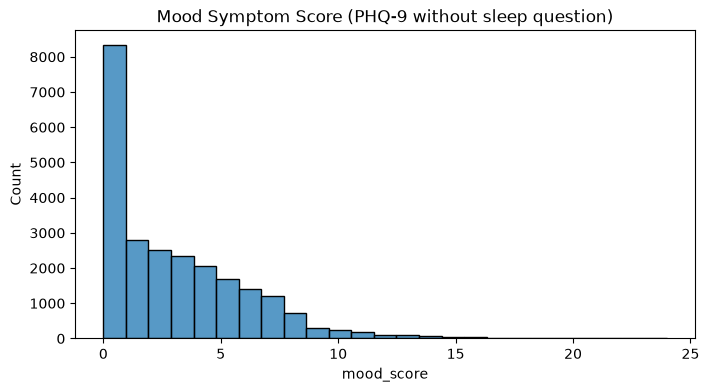

In [55]:
plt.figure(figsize=(8, 4))
sns.histplot(df["mood_score"], bins=25)
plt.title("Mood Symptom Score (PHQ-9 without sleep question)")
plt.show()

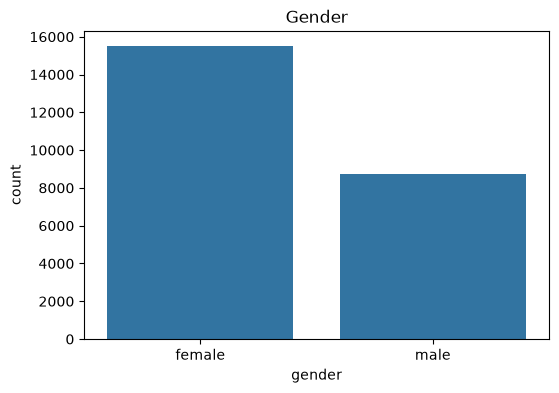

In [56]:
plt.figure(figsize=(6, 4))
sns.countplot(x="gender", data=df)
plt.title("Gender")
plt.show()

In [57]:
sleep_summary = df.groupby("sleep_group", observed=True)[["mood_score", "anxiety_score", "pss_total"]].mean().round(2)
sleep_summary["students"] = df["sleep_group"].value_counts()
print(sleep_summary)

                    mood_score  anxiety_score  pss_total  students
sleep_group                                                       
No problem                2.37           1.50      19.24     22058
Mild                      6.86           5.56      26.99      1916
Moderate or severe       10.61           9.30      30.82       278


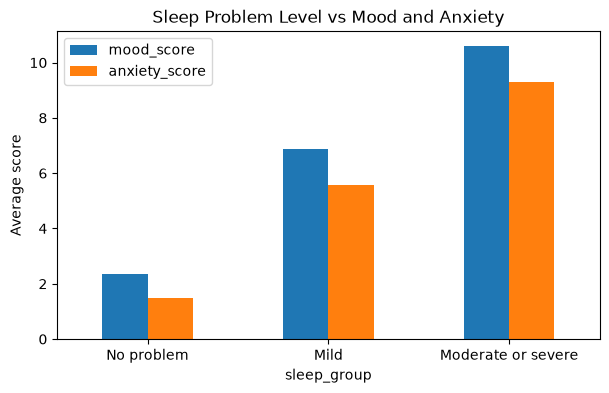

In [58]:
sleep_summary[["mood_score", "anxiety_score"]].plot(kind="bar", figsize=(7, 4))
plt.title("Sleep Problem Level vs Mood and Anxiety")
plt.ylabel("Average score")
plt.xticks(rotation=0)
plt.show()

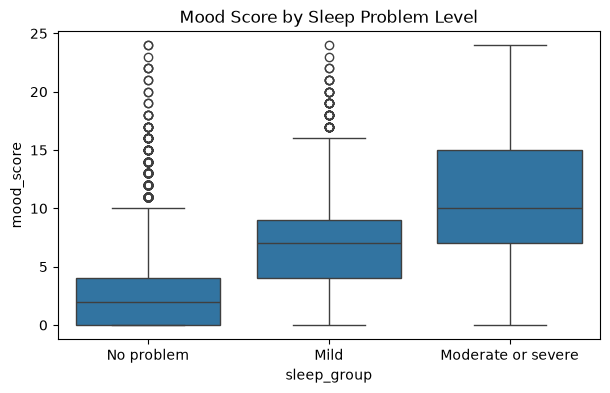

In [59]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="sleep_group", y="mood_score", data=df)
plt.title("Mood Score by Sleep Problem Level")
plt.show()

In [60]:
print(pd.crosstab(df["sleep_group"], df["low_mood"], normalize="index").round(3))

low_mood                0      1
sleep_group                     
No problem          0.793  0.207
Mild                0.262  0.738
Moderate or severe  0.147  0.853


In [61]:
for col in ["gender", "smoke", "drink"]:
    print("\n", col)
    print(pd.crosstab(df[col], df["low_mood"], normalize="index").round(3))


 gender
low_mood      0      1
gender                
female    0.738  0.262
male      0.755  0.245

 smoke
low_mood                                                0      1
smoke                                                           
current smoker (cumulative smoking >10 packs)       0.627  0.373
former smoker (cumulative smoking >10 packs), b...  0.624  0.376
never smokes                                        0.752  0.248
occasional smoker (cumulative smoking <10 packs)    0.647  0.353

 drink
low_mood                                                0      1
drink                                                           
current regular drinker (more than once a week)     0.548  0.452
drank in the past (more than once a week), but ...  0.604  0.396
drinks occasionally (less than once a week)         0.682  0.318
never drinks                                        0.777  0.223


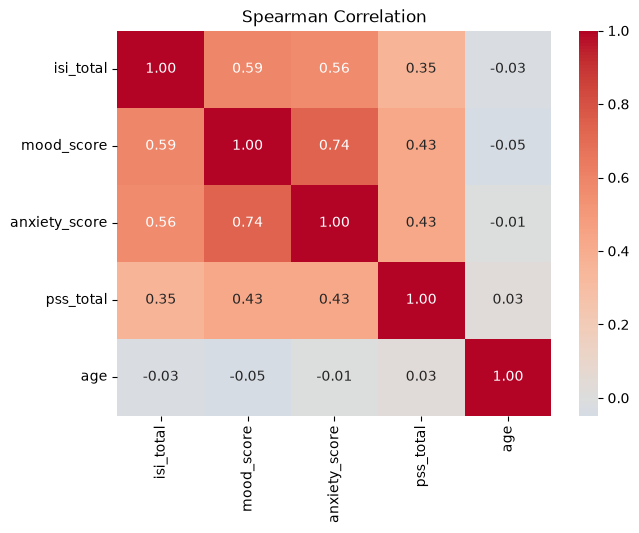

In [62]:
corr_cols = ["isi_total", "mood_score", "anxiety_score", "pss_total", "age"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman Correlation")
plt.show()

In [63]:
isi_cols = ["isi_" + str(i) for i in range(1, 8)]
print(df[isi_cols + ["mood_score"]].corr(method="spearman")["mood_score"].drop("mood_score").round(2))

isi_1    0.47
isi_2    0.41
isi_3    0.33
isi_4    0.50
isi_5    0.48
isi_6    0.30
isi_7    0.47
Name: mood_score, dtype: float64


In [64]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [65]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [66]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [67]:
isi_cols = ["isi_" + str(i) for i in range(1, 8)]
features = isi_cols + ["age", "gender", "smoke", "drink"]
print(features)

['isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'age', 'gender', 'smoke', 'drink']


In [68]:
X = df[features]
y = df["low_mood"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (24252, 11)
Target shape: (24252,)


In [69]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_7552\1671139452.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [70]:
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'age']
Categorical columns: ['gender', 'smoke', 'drink']


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [72]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Low mood in training set (%):", round(y_train.mean() * 100, 2))
print("Low mood in testing set (%):", round(y_test.mean() * 100, 2))

Training rows: 19401
Testing rows: 4851
Low mood in training set (%): 25.61
Low mood in testing set (%): 25.62


In [73]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

Low mood students are only about a quarter of the data, so accuracy alone can look good even for a model that never finds them. A baseline model that always predicts "not low" is added for comparison, and the other models use class_weight="balanced".

In [74]:
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}


Model: Baseline

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.74      1.00      0.85      3608
    Low mood       0.00      0.00      0.00      1243

    accuracy                           0.74      4851
   macro avg       0.37      0.50      0.43      4851
weighted avg       0.55      0.74      0.63      4851



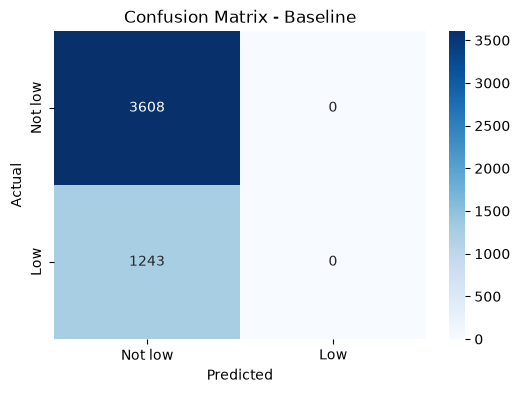


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.80      0.83      3608
    Low mood       0.53      0.67      0.59      1243

    accuracy                           0.76      4851
   macro avg       0.70      0.73      0.71      4851
weighted avg       0.79      0.76      0.77      4851



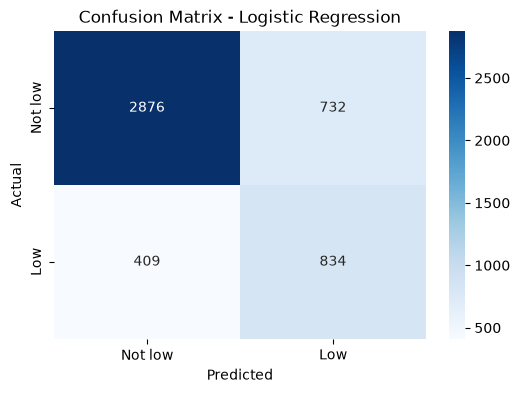


Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.75      0.81      3608
    Low mood       0.49      0.71      0.58      1243

    accuracy                           0.74      4851
   macro avg       0.69      0.73      0.69      4851
weighted avg       0.78      0.74      0.75      4851



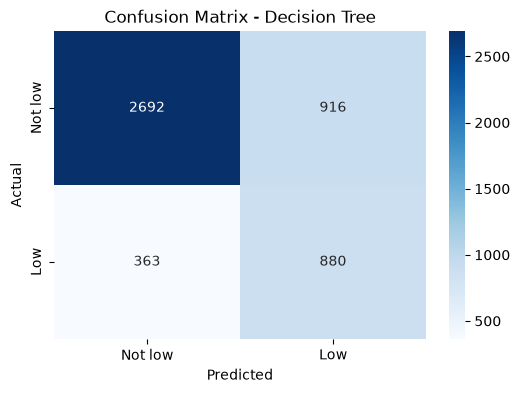


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.77      0.82      3608
    Low mood       0.51      0.69      0.59      1243

    accuracy                           0.75      4851
   macro avg       0.69      0.73      0.70      4851
weighted avg       0.78      0.75      0.76      4851



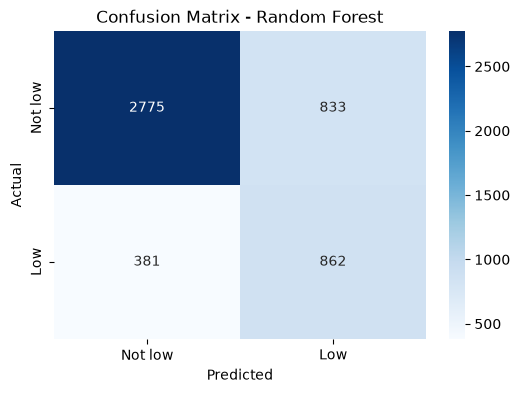

In [75]:
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2),
        "ROC-AUC": round(auc, 3)
    })
    print("\n", "=" * 50)
    print("Model:", name)
    print("=" * 50)
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Not low mood", "Low mood"],
        zero_division=0
    ))
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not low", "Low"],
        yticklabels=["Not low", "Low"]
    )
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [76]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score (%)",
    ascending=False
)
print("\nFinal Model Comparison:")
print(results_df.to_string(index=False))


Final Model Comparison:
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  ROC-AUC
Logistic Regression         76.48          53.26       67.10         59.38    0.806
      Random Forest         74.97          50.86       69.35         58.68    0.808
      Decision Tree         73.63          49.00       70.80         57.91    0.797
           Baseline         74.38           0.00        0.00          0.00    0.500


In [77]:
best_model = results_df.iloc[0]
print("Best Model:", best_model["Model"])
print("Best F1 Score:", best_model["F1 Score (%)"], "%")
print("Best Accuracy:", best_model["Accuracy (%)"], "%")
print("Precision of best model:", best_model["Precision (%)"], "%")
print("Recall of best model:", best_model["Recall (%)"], "%")

Best Model: Logistic Regression
Best F1 Score: 59.38 %
Best Accuracy: 76.48 %
Precision of best model: 53.26 %
Recall of best model: 67.1 %


The sleep-only model is checked more carefully now. Instead of one train/test split, 5-fold cross-validation is used so the score does not depend on a lucky split.

In [78]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
import os
import joblib
import json

In [79]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [80]:
sleep_lr = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [81]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
cv_scores = cross_validate(sleep_lr, X, y, cv=cv, scoring=scoring)

In [82]:
print("Sleep-only Logistic Regression (5-fold cross-validation)")
for metric in scoring:
    mean = cv_scores["test_" + metric].mean()
    std = cv_scores["test_" + metric].std()
    if metric == "roc_auc":
        print(metric, ":", round(mean, 3), "+/-", round(std, 3))
    else:
        print(metric, ":", round(mean * 100, 2), "% +/-", round(std * 100, 2))

Sleep-only Logistic Regression (5-fold cross-validation)
accuracy : 77.08 % +/- 0.52
precision : 54.18 % +/- 0.82
recall : 68.11 % +/- 1.4
f1 : 60.35 % +/- 0.97
roc_auc : 0.815 +/- 0.008


Next, the models are tuned with GridSearchCV. If tuning helps, the ROC-AUC should go up clearly.

In [83]:
param_grid_lr = {"model__C": [0.01, 0.1, 1, 10]}
gs_lr = GridSearchCV(sleep_lr, param_grid_lr, cv=cv, scoring="roc_auc", n_jobs=-1)
gs_lr.fit(X_train, y_train)
print("Best Logistic Regression parameters:", gs_lr.best_params_)
print("Best cross-validated ROC-AUC:", round(gs_lr.best_score_, 3))

Best Logistic Regression parameters: {'model__C': 0.01}
Best cross-validated ROC-AUC: 0.817


In [84]:
sleep_rf = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1))
])
param_grid_rf = {
    "model__max_depth": [4, 6, 8],
    "model__min_samples_leaf": [10, 30, 60]
}
gs_rf = GridSearchCV(sleep_rf, param_grid_rf, cv=cv, scoring="roc_auc", n_jobs=-1)
gs_rf.fit(X_train, y_train)
print("Best Random Forest parameters:", gs_rf.best_params_)
print("Best cross-validated ROC-AUC:", round(gs_rf.best_score_, 3))

Best Random Forest parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 30}
Best cross-validated ROC-AUC: 0.818


In [85]:
default_lr = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
default_lr.fit(X_train, y_train)

tuned_models = {
    "Logistic Regression (default)": default_lr,
    "Logistic Regression (tuned)": gs_lr.best_estimator_,
    "Random Forest (tuned)": gs_rf.best_estimator_
}

tuning_results = []
for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    tuning_results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "F1 Score (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 3)
    })
tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))

                        Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  ROC-AUC
Logistic Regression (default)         76.48          53.26       67.10         59.38    0.806
  Logistic Regression (tuned)         76.38          53.10       66.93         59.22    0.806
        Random Forest (tuned)         74.67          50.40       70.39         58.74    0.809


Accuracy can also be pushed up by raising the decision threshold, but this has a cost. The table below shows what happens to precision and recall for low mood students.

In [86]:
probs = default_lr.predict_proba(X_test)[:, 1]
threshold_results = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (probs >= t).astype(int)
    threshold_results.append({
        "Threshold": t,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "F1 Score (%)": round(f1_score(y_test, y_pred) * 100, 2)
    })
threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.to_string(index=False))

 Threshold  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
       0.3         63.06          39.75       85.60         54.29
       0.4         71.28          46.32       75.95         57.54
       0.5         76.48          53.26       67.10         59.38
       0.6         78.87          58.91       58.00         58.45
       0.7         79.63          64.15       46.50         53.92


In [87]:
pss_raw = pd.read_csv("dataset/pss.csv")
pss_items = pss_raw[["export_id"] + ["question" + str(i) for i in range(1, 15)]].copy()
pss_items.columns = ["export_id"] + ["pss_" + str(i) for i in range(1, 15)]
pss_cols = ["pss_" + str(i) for i in range(1, 15)]
print(pss_items.head())

   export_id  pss_1  pss_2  pss_3  pss_4  pss_5  pss_6  pss_7  pss_8  pss_9  \
0      61793      1      1      1      1      1      1      1      1      1   
1      61809      2      1      1      5      5      2      4      2      2   
2      61737      1      1      1      1      1      1      1      1      1   
3      61738      1      1      1      5      5      5      5      1      5   
4      61739      1      1      2      2      2      1      3      2      4   

   pss_10  pss_11  pss_12  pss_13  pss_14  
0       1       1       3       1       1  
1       5       1       2       2       1  
2       1       1       5       1       1  
3       5       1       1       5       1  
4       2       3       3       2       2  


In [88]:
print("PSS item range:", pss_items[pss_cols].min().min(), "to", pss_items[pss_cols].max().max())
print("PSS total matches item sum minus 14:", ((pss_items[pss_cols].sum(axis=1) - 14) == pss_raw["score"]).mean())

PSS item range: 1 to 5
PSS total matches item sum minus 14: 0.9999588341840935


In [89]:
df_ext = df.merge(pss_items, on="export_id")
y_ext = df_ext["low_mood"]
print("Dataset shape:", df_ext.shape)

Dataset shape: (24252, 52)


Forward selection: stress questions are added one at a time, and each time the question that improves the cross-validated ROC-AUC the most is kept.

The positively worded PSS questions (4, 5, 6, 7, 9, 10 and 13, for example pss_13: being able to control the way you spend your time) are left out. In this data a higher answer on these questions goes with more low mood symptoms, which is the opposite of what the wording means, so they would confuse users in the app. Only the negatively worded stress questions can be selected.

In [90]:
excluded_cols = ["pss_4", "pss_5", "pss_6", "pss_7", "pss_9", "pss_10", "pss_13"]

In [91]:
chosen = []
for step in range(4):
    best_auc = 0
    best_col = None
    for col in pss_cols:
        if col in chosen or col in excluded_cols:
            continue
        cols = num_cols + chosen + [col]
        prep = ColumnTransformer([
            ("num", StandardScaler(), cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])
        pipe = Pipeline([
            ("preprocessing", prep),
            ("model", LogisticRegression(max_iter=1000))
        ])
        probs = cross_val_predict(pipe, df_ext[cols + cat_cols], y_ext, cv=cv, method="predict_proba")[:, 1]
        auc = roc_auc_score(y_ext, probs)
        if auc > best_auc:
            best_auc = auc
            best_col = col
    chosen.append(best_col)
    print("Step", step + 1, "- added", best_col, "- ROC-AUC:", round(best_auc, 3))

Step 1 - added pss_2 - ROC-AUC: 0.861
Step 2 - added pss_3 - ROC-AUC: 0.871
Step 3 - added pss_14 - ROC-AUC: 0.876
Step 4 - added pss_1 - ROC-AUC: 0.878


In [92]:
extra_cols = chosen
print("Selected stress questions:", extra_cols)

Selected stress questions: ['pss_2', 'pss_3', 'pss_14', 'pss_1']


In [93]:
feature_sets = {
    "Sleep only (7 questions)": [],
    "Sleep + 2 stress questions": extra_cols[:2],
    "Sleep + 4 stress questions": extra_cols
}

comparison = []
for name, extra in feature_sets.items():
    cols = num_cols + extra
    prep = ColumnTransformer([
        ("num", StandardScaler(), cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])
    pipe = Pipeline([
        ("preprocessing", prep),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])
    scores = cross_validate(pipe, df_ext[cols + cat_cols], y_ext, cv=cv, scoring=scoring)
    comparison.append({
        "Features": name,
        "Accuracy (%)": round(scores["test_accuracy"].mean() * 100, 2),
        "Precision (%)": round(scores["test_precision"].mean() * 100, 2),
        "Recall (%)": round(scores["test_recall"].mean() * 100, 2),
        "F1 Score (%)": round(scores["test_f1"].mean() * 100, 2),
        "ROC-AUC": round(scores["test_roc_auc"].mean(), 3)
    })
comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))

                  Features  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  ROC-AUC
  Sleep only (7 questions)         77.08          54.18       68.11         60.35    0.815
Sleep + 2 stress questions         79.95          58.17       77.33         66.39    0.871
Sleep + 4 stress questions         80.59          59.04       79.07         67.60    0.878


The final model uses the 7 sleep questions, the 4 selected stress questions, age, gender, smoking and drinking. All four models are trained again with these features.

In [95]:
features_final = isi_cols + extra_cols + ["age", "gender", "smoke", "drink"]
print(features_final)

['isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'pss_2', 'pss_3', 'pss_14', 'pss_1', 'age', 'gender', 'smoke', 'drink']


In [96]:
X_final = df_ext[features_final]
y_final = df_ext["low_mood"]
print("Features shape:", X_final.shape)
print("Target shape:", y_final.shape)

Features shape: (24252, 15)
Target shape: (24252,)


In [97]:
num_cols_final = isi_cols + extra_cols + ["age"]
cat_cols_final = ["gender", "smoke", "drink"]

In [98]:
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_final,
    y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final
)

In [99]:
print("Training rows:", X_train_f.shape[0])
print("Testing rows:", X_test_f.shape[0])
print("Low mood in training set (%):", round(y_train_f.mean() * 100, 2))
print("Low mood in testing set (%):", round(y_test_f.mean() * 100, 2))

Training rows: 19401
Testing rows: 4851
Low mood in training set (%): 25.61
Low mood in testing set (%): 25.62


In [100]:
preprocessor_final = ColumnTransformer([
    ("num", StandardScaler(), num_cols_final),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_final)
])

In [101]:
models_final = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}


Model: Baseline

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.74      1.00      0.85      3608
    Low mood       0.00      0.00      0.00      1243

    accuracy                           0.74      4851
   macro avg       0.37      0.50      0.43      4851
weighted avg       0.55      0.74      0.63      4851



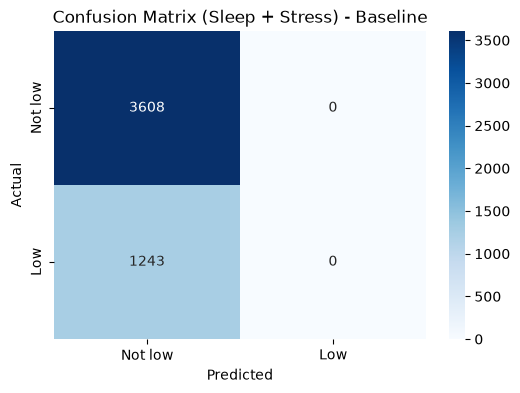


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.92      0.81      0.86      3608
    Low mood       0.59      0.79      0.67      1243

    accuracy                           0.80      4851
   macro avg       0.75      0.80      0.77      4851
weighted avg       0.83      0.80      0.81      4851



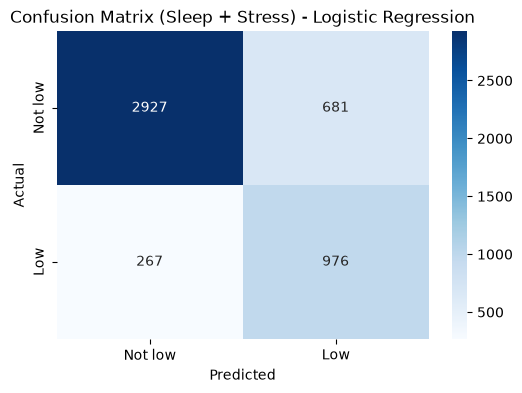


Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.93      0.73      0.82      3608
    Low mood       0.52      0.84      0.64      1243

    accuracy                           0.76      4851
   macro avg       0.73      0.79      0.73      4851
weighted avg       0.83      0.76      0.77      4851



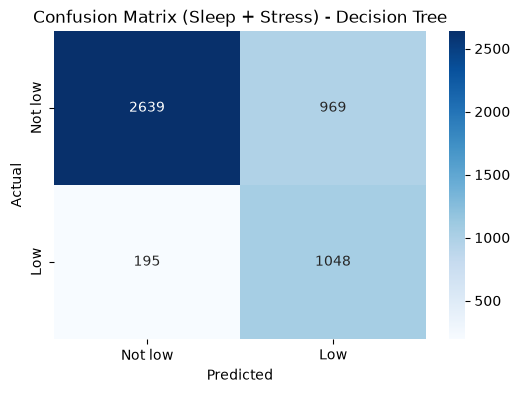


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.92      0.80      0.85      3608
    Low mood       0.58      0.79      0.67      1243

    accuracy                           0.80      4851
   macro avg       0.75      0.79      0.76      4851
weighted avg       0.83      0.80      0.81      4851



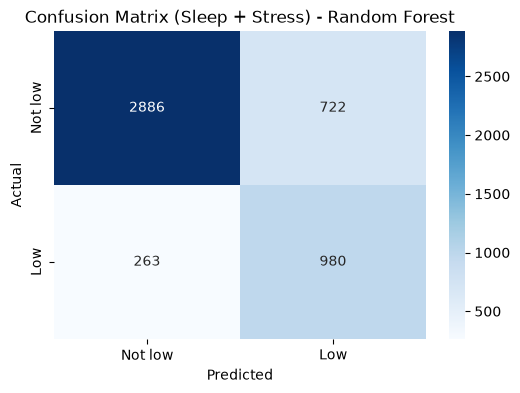

In [102]:
results_final = []
for name, model in models_final.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor_final),
        ("model", model)
    ])
    pipeline.fit(X_train_f, y_train_f)
    y_pred = pipeline.predict(X_test_f)
    y_prob = pipeline.predict_proba(X_test_f)[:, 1]
    accuracy = accuracy_score(y_test_f, y_pred)
    precision = precision_score(y_test_f, y_pred, zero_division=0)
    recall = recall_score(y_test_f, y_pred, zero_division=0)
    f1 = f1_score(y_test_f, y_pred, zero_division=0)
    auc = roc_auc_score(y_test_f, y_prob)
    results_final.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2),
        "ROC-AUC": round(auc, 3)
    })
    print("\n", "=" * 50)
    print("Model:", name)
    print("=" * 50)
    print("\nClassification Report:")
    print(classification_report(
        y_test_f,
        y_pred,
        labels=[0, 1],
        target_names=["Not low mood", "Low mood"],
        zero_division=0
    ))
    cm = confusion_matrix(y_test_f, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not low", "Low"],
        yticklabels=["Not low", "Low"]
    )
    plt.title("Confusion Matrix (Sleep + Stress) - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [103]:
results_final_df = pd.DataFrame(results_final)
results_final_df = results_final_df.sort_values(
    by="F1 Score (%)",
    ascending=False
)
print("\nFinal Model Comparison (Sleep + 4 stress questions):")
print(results_final_df.to_string(index=False))


Final Model Comparison (Sleep + 4 stress questions):
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  ROC-AUC
Logistic Regression         80.46          58.90       78.52         67.31    0.875
      Random Forest         79.69          57.58       78.84         66.55    0.875
      Decision Tree         76.00          51.96       84.31         64.29    0.854
           Baseline         74.38           0.00        0.00          0.00    0.500


In [104]:
best_final = results_final_df.iloc[0]
best_sleep_only = results_df.iloc[0]
print("Best model (sleep only):", best_sleep_only["Model"])
print("Best model (sleep + stress):", best_final["Model"])
print()
for metric in ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)", "ROC-AUC"]:
    print(metric, ":", best_sleep_only[metric], "->", best_final[metric])

Best model (sleep only): Logistic Regression
Best model (sleep + stress): Logistic Regression

Accuracy (%) : 76.48 -> 80.46
Precision (%) : 53.26 -> 58.9
Recall (%) : 67.1 -> 78.52
F1 Score (%) : 59.38 -> 67.31
ROC-AUC : 0.806 -> 0.875


The best model is trained on the full data and saved. The feature list and answer ranges are saved in a json file, so the backend and the frontend use the same inputs.

In [105]:
best_model_name = results_final_df.iloc[0]["Model"]
print("Selected model:", best_model_name)
final_model = Pipeline([
    ("preprocessing", preprocessor_final),
    ("model", models_final[best_model_name])
])
final_model.fit(X_final, y_final)
joblib.dump(final_model, "best_model.pkl")
results_final_df.to_csv("model_results.csv", index=False)
print("Model saved successfully!")

Selected model: Logistic Regression
Model saved successfully!


In [106]:
model_info = {
    "model": best_model_name,
    "features": features_final,
    "sleep_questions": {"columns": isi_cols, "answer_range": [0, 4]},
    "stress_questions": {"columns": extra_cols, "answer_range": [1, 5]},
    "age_range": [16, 40],
    "categories": {
        "gender": sorted(df_ext["gender"].unique().tolist()),
        "smoke": sorted(df_ext["smoke"].unique().tolist()),
        "drink": sorted(df_ext["drink"].unique().tolist())
    },
    "risk_levels": {"steady": [0, 40], "disturbed": [40, 60], "needs_attention": [60, 100]}
}
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print(json.dumps(model_info, indent=2))

{
  "model": "Logistic Regression",
  "features": [
    "isi_1",
    "isi_2",
    "isi_3",
    "isi_4",
    "isi_5",
    "isi_6",
    "isi_7",
    "pss_2",
    "pss_3",
    "pss_14",
    "pss_1",
    "age",
    "gender",
    "smoke",
    "drink"
  ],
  "sleep_questions": {
    "columns": [
      "isi_1",
      "isi_2",
      "isi_3",
      "isi_4",
      "isi_5",
      "isi_6",
      "isi_7"
    ],
    "answer_range": [
      0,
      4
    ]
  },
  "stress_questions": {
    "columns": [
      "pss_2",
      "pss_3",
      "pss_14",
      "pss_1"
    ],
    "answer_range": [
      1,
      5
    ]
  },
  "age_range": [
    16,
    40
  ],
  "categories": {
    "gender": [
      "female",
      "male"
    ],
    "smoke": [
      "current smoker (cumulative smoking >10 packs)",
      "former smoker (cumulative smoking >10 packs), but not in the past year",
      "never smokes",
      "occasional smoker (cumulative smoking <10 packs)"
    ],
    "drink": [
      "current regular drinker (

Which questions matter most? Logistic Regression coefficients are used because they are easy to read. A larger positive value means a higher answer goes with a higher chance of low mood. This shows association only, not cause.

In [107]:
lr_final = Pipeline([
    ("preprocessing", preprocessor_final),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
lr_final.fit(X_final, y_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

In [108]:
feature_names = lr_final.named_steps["preprocessing"].get_feature_names_out()
coefficients = lr_final.named_steps["model"].coef_[0]
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coef_df["Feature"] = coef_df["Feature"].str.replace("num__", "").str.replace("cat__", "")
coef_df = coef_df.sort_values(by="Coefficient", ascending=False)
print(coef_df.head(10).to_string(index=False))

                                                                  Feature  Coefficient
                                                                    pss_2     0.511772
                                                                    pss_3     0.507266
                                                                   pss_14     0.397032
                                                                    pss_1     0.292879
                    drink_current regular drinker (more than once a week)     0.282362
                                                                    isi_6     0.220605
                                                                    isi_2     0.216203
                                                                    isi_1     0.206669
                                                                    isi_3     0.169974
drink_drank in the past (more than once a week), but not in the past year     0.117739


In [109]:
question_coef = coef_df[coef_df["Feature"].isin(isi_cols + extra_cols)].copy()
sleep_total = question_coef[question_coef["Feature"].isin(isi_cols)]["Coefficient"].abs().sum()
stress_total = question_coef[question_coef["Feature"].isin(extra_cols)]["Coefficient"].abs().sum()
print("Combined weight of sleep questions:", round(sleep_total, 2))
print("Combined weight of stress questions:", round(stress_total, 2))
print("Sleep share (%):", round(sleep_total / (sleep_total + stress_total) * 100, 1))

Combined weight of sleep questions: 1.11
Combined weight of stress questions: 1.71
Sleep share (%): 39.4


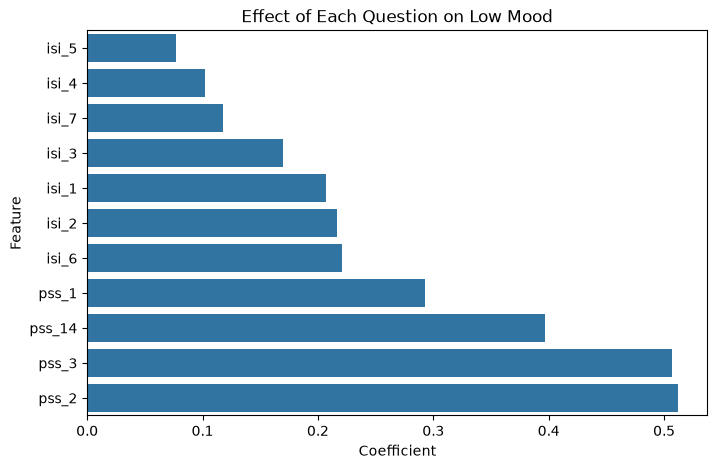

In [110]:
plt.figure(figsize=(8, 5))
sns.barplot(x="Coefficient", y="Feature", data=question_coef.sort_values(by="Coefficient"))
plt.title("Effect of Each Question on Low Mood")
plt.show()

Demo: the user answers 7 sleep questions (0 to 4) and 4 stress questions (1 to 5). The score is a risk score from 0 to 100, not a real probability, because class weights were used in training.

In [111]:
print("Current folder:", os.getcwd())
print("Model file exists:", os.path.exists("best_model.pkl"))

Current folder: c:\Users\Bhoomi\OneDrive\Desktop\Final group task\Mindora\SleepSync – Sleep & Mood Relationship Analyzer
Model file exists: True


In [112]:
loaded_model = joblib.load("best_model.pkl")
print("Model loaded:", best_model_name)

Model loaded: Logistic Regression


In [113]:
isi_names = {
    "isi_1": "Difficulty falling asleep",
    "isi_2": "Difficulty staying asleep",
    "isi_3": "Waking up too early",
    "isi_4": "Dissatisfaction with sleep",
    "isi_5": "Sleep problem noticeable to others",
    "isi_6": "Worry about sleep",
    "isi_7": "Sleep problem affects daily life"
}

In [114]:
def mindora_insight(sleep_answers, stress_answers, age=20, gender="female", smoke="never smokes", drink="never drinks"):
    row = pd.DataFrame([sleep_answers + stress_answers + [age, gender, smoke, drink]], columns=features_final)
    score = loaded_model.predict_proba(row)[0][1] * 100
    worst = max(zip(isi_names.values(), sleep_answers), key=lambda t: t[1])[0]
    print("Low mood risk score:", round(score), "/ 100")
    if score >= 60:
        print("Level: needs attention")
        print("Your answers are similar to students who often report low mood. Biggest sleep problem:", worst + ".")
        print("Try a fixed sleep time this week and consider talking to someone you trust.")
        print("Free and confidential support, 24x7: Tele-MANAS 14416. If you are in immediate danger, call 112.")
    elif score >= 40:
        print("Level: disturbed")
        print("Your answers are similar to some students who report low mood (" + worst + "). Try less screen time before bed.")
    else:
        print("Level: steady")
        print("Your sleep and stress pattern looks fine. Keep it up!")

In [115]:
mindora_insight([3, 3, 2, 3, 2, 3, 3], [4, 4, 3, 4])

Low mood risk score: 100 / 100
Level: needs attention
Your answers are similar to students who often report low mood. Biggest sleep problem: Difficulty falling asleep.
Try a fixed sleep time this week and consider talking to someone you trust.
Free and confidential support, 24x7: Tele-MANAS 14416. If you are in immediate danger, call 112.


In [116]:
mindora_insight([0, 0, 0, 1, 0, 0, 0], [1, 1, 2, 1])

Low mood risk score: 11 / 100
Level: steady
Your sleep and stress pattern looks fine. Keep it up!


Conclusion

The project started with a sleep-only model. The seven Insomnia Severity Index questions, age, gender, smoking and drinking were used to predict whether a student shows low mood symptoms (PHQ-9 score of 5 or more, without the sleep question). Logistic Regression was the best model with 76.48% accuracy, 67.1% recall and ROC-AUC of 0.806 on the test set (77.08% accuracy, 68.11% recall and ROC-AUC of 0.815 in 5-fold cross-validation).

Tuning with GridSearchCV did not help (tuned Logistic Regression F1 59.22%, tuned Random Forest ROC-AUC 0.809). Raising the threshold to 0.7 increased accuracy to 79.63%, but recall dropped to 46.5%, so many more low mood students would be missed. The threshold was kept at 0.5. The sleep questions alone hold only a limited amount of information about mood.

Four stress questions from the PSS file (pss_2, pss_3, pss_14, pss_1) were chosen with forward selection and added to the model. The positively worded PSS questions (4 to 7, 9, 10 and 13) were left out because their answers go in the opposite direction of their meaning in this data. The final Logistic Regression reached 80.46% accuracy, 78.52% recall, F1 score of 67.31% and ROC-AUC of 0.875, compared with 76.48%, 67.1%, 59.38% and 0.806 before. Cross-validation shows the same picture (ROC-AUC 0.815 with sleep only and 0.878 with sleep and four stress questions).

Important: the four stress questions carry about 1.5 times the weight of the seven sleep questions together (sleep share 39.4%). So the final model is a sleep and stress model, and sleep is no longer the main driver. The sleep questions stay in the app because they show which sleep problem is linked with low mood.

Limitations: each student has only one row, so the model shows a relationship across students and not day by day changes. Most students are around 18 to 22 years old with a bachelor's degree. The four stress questions were selected on the same data that was used for scoring, so the real accuracy may be slightly lower. A link between sleep, stress and mood does not prove that one causes the other. The low mood flag is a wellness screening-style indicator and not a diagnosis. The risk score is not a real probability because class weights were used in training.

Data source: Su et al. (2024), Temporal dynamics in psychological assessments: a novel dataset with scales and response times, Scientific Data. Data on Zenodo (DOI 10.5281/zenodo.10423537), license CC BY 4.0.